# Assignment 1: Parkinson's Disease Classification

Jasper Lim (9117038)

This notebook predicts whether a patient is likely to have Parkinson's disease from anonymized speech features. It follows all seven assignment questions.

## Question 1: Data analysis and preprocessing

The dataset uses `class` as the target (`1` = Parkinson's disease, `0` = healthy). `id` is an identifier and is removed because it is not a patient measurement. The first CSV row contains descriptive metadata, so the data header begins on the second row.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

DATA_PATH = Path('pd_speech_features.csv')
OUTPUT_PATH = Path('all_model_test_predictions.csv')

df = pd.read_csv(DATA_PATH, skiprows=1)
print(f'Dataset shape: {df.shape}')
print('Target counts:')
print(df['class'].value_counts().sort_index())
df.head()

Dataset shape: (756, 755)
Target counts:
class
0    192
1    564
Name: count, dtype: int64


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [2]:
# Data quality and preprocessing checks
print(f'Missing values: {df.isna().sum().sum()}')
print(f'Duplicate rows: {df.duplicated().sum()}')
print(f'Unique patient IDs: {df["id"].nunique()}')

df = df.drop_duplicates().drop(columns=['id'])

X = df.drop(columns=['class'])
y = df['class'].astype(int)

print(f'Preprocessed shape: {df.shape}')
print(f'Feature count: {X.shape[1]}')

Missing values: 0
Duplicate rows: 1
Unique patient IDs: 252


Preprocessed shape: (755, 754)
Feature count: 753


### Standardization

Numeric features are standardized with `StandardScaler`. The scaler is included in every model pipeline and is fit only on training data, preventing test-data leakage.

## Question 2: 80/20 train-test split

The data are split with 80% for training and 20% for testing. `stratify=y` preserves the healthy/Parkinson's class proportions.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, train_size=0.80, random_state=42, stratify=y
)

print(f'Training samples: {X_train.shape[0]}')
print(f'Test samples: {X_test.shape[0]}')
print(f'Training class counts: {y_train.value_counts().to_dict()}')
print(f'Test class counts: {y_test.value_counts().to_dict()}')

Training samples: 604
Test samples: 151
Training class counts: {1: 450, 0: 154}
Test class counts: {1: 113, 0: 38}


## Question 3: Model training

Four classifiers are trained: K-Nearest Neighbors, Random Forest, Support Vector Machine, and Decision Tree.

In [4]:
models = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestClassifier(n_estimators=200, random_state=42))
    ]),
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', random_state=42))
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeClassifier(random_state=42))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'Trained: {name}')

Trained: KNN


Trained: Random Forest
Trained: SVM


Trained: Decision Tree


## Question 4: Test-set predictions

Each trained pipeline predicts the class labels for the held-out test set.

In [5]:
predictions = {}
for name, model in models.items():
    predictions[name] = model.predict(X_test)

predictions_df = pd.DataFrame(predictions)
predictions_df.insert(0, 'Actual', y_test.to_numpy())
predictions_df.head(10)

,Actual,KNN,Random Forest,SVM,Decision Tree
0,1,0,1,1,1
1,1,1,1,1,1
2,0,0,0,0,0
3,1,1,1,1,1
4,0,0,0,0,0
5,0,0,0,0,1
6,1,1,1,1,0
7,1,1,1,1,1
8,1,1,1,1,1
9,0,1,0,0,0


## Question 5: Predictive system for a new sample

The first test-row feature values simulate a new patient. For each model, `1` means predicted Parkinson's disease and `0` means predicted healthy.

In [6]:
new_sample = X_test.iloc[[0]]

new_sample_predictions = {}
for name, model in models.items():
    predicted_class = int(model.predict(new_sample)[0])
    new_sample_predictions[name] = predicted_class

pd.DataFrame([new_sample_predictions], index=['New patient sample'])

,KNN,Random Forest,SVM,Decision Tree
New patient sample,0,1,1,1


## Question 6: Accuracy, confusion matrices, and classification reports

Accuracy is measured on the 20% test set. Confusion matrices show true and false classifications; class `1` is Parkinson's disease.

In [7]:
accuracy_results = {}

for name in models:
    y_pred = predictions[name]
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_results[name] = accuracy

    print(f'\n===== {name} =====')
    print(f'Accuracy: {accuracy:.4f}')

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print('Confusion matrix:')
    print(cm)

    print('Classification report:')
    print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'Parkinson\'s (1)']))


===== KNN =====
Accuracy: 0.8344
Confusion matrix:
[[ 17  21]
 [  4 109]]
Classification report:
                 precision    recall  f1-score   support

    Healthy (0)       0.81      0.45      0.58        38
Parkinson's (1)       0.84      0.96      0.90       113

       accuracy                           0.83       151
      macro avg       0.82      0.71      0.74       151
   weighted avg       0.83      0.83      0.82       151


===== Random Forest =====
Accuracy: 0.8543
Confusion matrix:
[[ 20  18]
 [  4 109]]
Classification report:
                 precision    recall  f1-score   support

    Healthy (0)       0.83      0.53      0.65        38
Parkinson's (1)       0.86      0.96      0.91       113

       accuracy                           0.85       151
      macro avg       0.85      0.75      0.78       151
   weighted avg       0.85      0.85      0.84       151


===== SVM =====
Accuracy: 0.8411
Confusion matrix:
[[ 16  22]
 [  2 111]]
Classification report:
      

In [8]:
accuracy_df = pd.DataFrame(
    {'Model': list(accuracy_results.keys()), 'Accuracy': list(accuracy_results.values())}
).sort_values('Accuracy', ascending=False)

best_model = accuracy_df.iloc[0]
print(f"Best model: {best_model['Model']} (accuracy = {best_model['Accuracy']:.4f})")
accuracy_df

Best model: Random Forest (accuracy = 0.8543)


,Model,Accuracy
1,Random Forest,0.854305
2,SVM,0.841060
0,KNN,0.834437
3,Decision Tree,0.814570


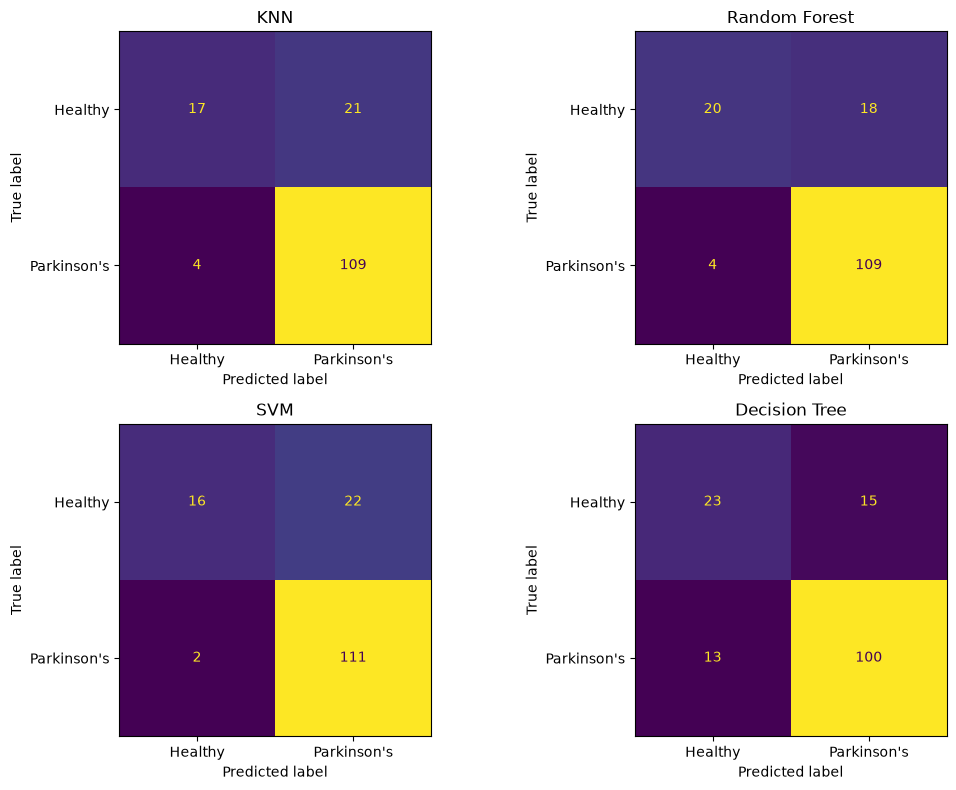

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()

for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Healthy', "Parkinson's"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Evaluation summary

The table in the previous cell ranks models by test accuracy. The confusion matrices and classification reports compare false negatives, false positives, precision, recall, and F1-score. The model with the highest test accuracy is selected as the best model.

## Question 7: Save test predictions

The test actual class and predictions from all four models are combined into one CSV.

In [10]:
predictions_df.to_csv(OUTPUT_PATH, index=False)
print(f'Saved test predictions to: {OUTPUT_PATH.resolve()}')
predictions_df

Saved test predictions to: C:\Users\User\Documents\conestoga\CSCN8000\CSCN8000-lab-submissions\students-submissions\9117038\a1\all_model_test_predictions.csv


,Actual,KNN,Random Forest,SVM,Decision Tree
0,1,0,1,1,1
1,1,1,1,1,1
2,0,0,0,0,0
3,1,1,1,1,1
4,0,0,0,0,0
...,...,...,...,...,...
146,1,1,1,1,0
147,0,1,0,1,1
148,1,1,1,1,1
149,1,1,1,1,1
